
# Lab 3: Supervised Machine Learning — Classification and Regression

**Course:** Artificial Intelligence Algorithms and Mathematics  
**Student Name:** Ubaid Ullah  
**Student ID:** 9110715  
**Section:** 1  

---

## 1. Introduction

This lab explores two supervised machine learning techniques to solve real-world prediction problems using Python and scikit-learn.

**Part A — Credit Card Fraud Detection**

The objective is to develop a Logistic Regression classification model that identifies potentially fraudulent credit card transactions. The model will be trained on 70% of the data and tested on the remaining 30%.

**Part B — Insurance Cost Prediction**

The objective is to develop a Linear Regression model that predicts individual medical insurance charges based on demographic and lifestyle characteristics. A 70/30 train-test split will also be applied.

## 2. Learning Objectives

By completing this lab, the following tasks will be demonstrated:

1. Load and explore real-world datasets using pandas.
2. Identify missing values, duplicates, and relevant data characteristics.
3. Perform appropriate preprocessing and exploratory data analysis (EDA).
4. Split each dataset into 70% training and 30% testing data.
5. Train Logistic Regression and Linear Regression models.
6. Evaluate model performance using suitable classification and regression metrics.
7. Visualize results and interpret the models' predictive performance.
8. Summarize key findings, limitations, and possible improvements.

## 3. Datasets

**Dataset A: Credit Card Fraud Detection**
- Source: Kaggle — Machine Learning Group, ULB
- File: `creditcard.csv`
- Target variable: `Class`
- Problem type: Binary Classification

**Dataset B: Medical Cost Personal Dataset**
- Source: Kaggle — Mirichoi
- File: `insurance.csv`
- Target variable: `charges`
- Problem type: Regression

Both datasets will be analyzed independently using the algorithms specified in the lab instructions.



## 4. Python Libraries and Environment Setup

This lab uses Python libraries for data manipulation, exploratory data analysis, visualization, and machine learning.

The main libraries include:

- **pandas:** Loading, cleaning, and analyzing datasets.
- **NumPy:** Numerical calculations and array operations.
- **Matplotlib:** Creating graphs and visualizations.
- **Seaborn:** Statistical visualizations and data exploration.
- **scikit-learn:** Data preprocessing, model training, and performance evaluation.

Additional scikit-learn components will be imported as needed for each prediction task.


In [1]:

# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Verify that the libraries are available
print("All required data analysis libraries imported successfully.")


All required data analysis libraries imported successfully.



---

## 5. Part A — Credit Card Fraud Detection

### 5.1 Dataset Loading and Initial Inspection

The Credit Card Fraud Detection dataset contains credit card transactions labeled as legitimate or fraudulent.

The target variable is `Class`:
- **0:** Legitimate transaction
- **1:** Fraudulent transaction

The dataset also contains `Time`, `Amount`, and anonymized numerical features (`V1` through `V28`).

In this section, the dataset is loaded using pandas, and its dimensions, column names, and first five records are examined to understand its structure before preprocessing.


In [2]:

# Load the credit card fraud dataset
creditcard_df = pd.read_csv("creditcard.csv")

# Display the dataset dimensions
print("Dataset Shape (Rows, Columns):", creditcard_df.shape)

# Display column names
print("\nColumn Names:")
print(creditcard_df.columns.tolist())

# Display the first five records
print("\nFirst Five Records:")
display(creditcard_df.head())


Dataset Shape (Rows, Columns): (284807, 31)

Column Names:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

First Five Records:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



### 5.2 Data Quality Assessment

Before training the classification model, the dataset is examined for potential data quality issues.

The following checks are performed:

1. **Data types:** Verify whether the features contain numerical or categorical values.
2. **Missing values:** Identify any incomplete records that may require treatment.
3. **Duplicate records:** Identify repeated transactions that could affect model evaluation.

These checks help determine which preprocessing steps are necessary. Any duplicate removal will be considered carefully because fraudulent transactions are rare.


In [3]:

# Examine dataset information and data types
print("Dataset Information:")
creditcard_df.info()

# Check missing values
print("\nMissing Values by Column:")
missing_values = creditcard_df.isnull().sum()
display(missing_values.to_frame(name="Missing Values"))

print("Total Missing Values:", missing_values.sum())

# Check duplicate records
duplicate_count = creditcard_df.duplicated().sum()
print("\nTotal Duplicate Records:", duplicate_count)


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  

,Missing Values
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Total Missing Values: 0

Total Duplicate Records: 1081



#### 5.2.1 Data Quality Findings

The initial data quality assessment produced the following findings:

- **Dataset size:** 284,807 transactions and 31 columns.
- **Data types:** 30 columns contain `float64` values, while the target variable `Class` contains `int64` values.
- **Missing values:** No missing values were detected in any column. Therefore, missing-value imputation is unnecessary.
- **Duplicate records:** 1,081 duplicate rows were identified, representing approximately 0.38% of the dataset.
- **Memory usage:** Approximately 67.4 MB.

**Interpretation:**

The dataset is suitable for further analysis because all features are numerical and there are no missing values. However, the presence of 1,081 duplicate records requires additional investigation.

Duplicate transactions will not be removed automatically because their distribution across legitimate and fraudulent classes must first be examined. This is particularly important for fraud detection, where fraudulent transactions are relatively rare.

The next step is to analyze the target variable distribution and investigate duplicate records by transaction class.



### 5.3 Class Distribution and Duplicate Analysis

Understanding the distribution of the target variable is essential for credit card fraud detection.

This analysis examines:

1. The number and percentage of legitimate and fraudulent transactions.
2. The distribution of duplicate records across both classes.

These findings will help determine whether class imbalance requires special consideration during model training and evaluation.


In [4]:

# Count transactions in each class
class_counts = creditcard_df["Class"].value_counts().sort_index()

# Calculate class percentages
class_percentages = (
    creditcard_df["Class"].value_counts(normalize=True)
    .sort_index() * 100
)

class_distribution = pd.DataFrame({
    "Transaction Count": class_counts,
    "Percentage (%)": class_percentages.round(4)
})

class_distribution.index = ["Legitimate (0)", "Fraudulent (1)"]

print("Transaction Class Distribution:")
display(class_distribution)

# Investigate duplicate records by class
duplicate_mask = creditcard_df.duplicated()

print("\nDuplicate Records by Class:")
print(
    creditcard_df.loc[duplicate_mask, "Class"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
)

print("\nTotal Duplicate Records:", duplicate_mask.sum())


Transaction Class Distribution:


,Transaction Count,Percentage (%)
Legitimate (0),284315,99.8273
Fraudulent (1),492,0.1727



Duplicate Records by Class:
Class
Legitimate    1062
Fraudulent      19
Name: count, dtype: int64

Total Duplicate Records: 1081



#### 5.3.1 Class Distribution and Duplicate Analysis Findings

The dataset contains 284,807 credit card transactions, distributed as follows:

| Transaction Type | Count | Percentage |
|---|---:|---:|
| Legitimate (Class 0) | 284,315 | 99.8273% |
| Fraudulent (Class 1) | 492 | 0.1727% |

**Key Findings:**

1. **Severe Class Imbalance:** Only 0.1727% of transactions are fraudulent. Therefore, classification accuracy alone may be misleading. A model that predicts every transaction as legitimate could achieve approximately 99.83% accuracy without detecting any fraud.

2. **Duplicate Records:** A total of 1,081 duplicate records were identified, including 1,062 legitimate and 19 fraudulent records.

3. **Preprocessing Decision:** Exact duplicate rows will be removed before splitting the dataset to reduce the possibility of identical observations appearing in both training and testing sets. However, because transaction identifiers are unavailable, we cannot confirm whether every identical row represents a repeated recording rather than a distinct transaction.

4. **Model Evaluation:** In addition to accuracy, precision, recall, F1-score, and the confusion matrix will be used to assess fraud detection performance.

5. **Train-Test Strategy:** A stratified 70/30 train-test split will be applied to preserve approximately the same fraud proportion in both datasets.

These decisions aim to provide a more reliable evaluation of the Logistic Regression classification model.


In [5]:

# Remove exact duplicate rows before train-test splitting
creditcard_clean_df = creditcard_df.drop_duplicates().copy()

# Compare the original and cleaned datasets
print("Original Dataset Shape:", creditcard_df.shape)
print("Cleaned Dataset Shape:", creditcard_clean_df.shape)

print("\nRecords Removed:",
      len(creditcard_df) - len(creditcard_clean_df))

# Verify that no duplicate rows remain
print("Remaining Duplicates:",
      creditcard_clean_df.duplicated().sum())

# Examine the class distribution after cleaning
print("\nClass Distribution After Cleaning:")
display(
    creditcard_clean_df["Class"]
    .value_counts()
    .sort_index()
    .rename(index={0: "Legitimate", 1: "Fraudulent"})
    .to_frame(name="Transaction Count")
)


Original Dataset Shape: (284807, 31)
Cleaned Dataset Shape: (283726, 31)

Records Removed: 1081
Remaining Duplicates: 0

Class Distribution After Cleaning:


,Transaction Count
Class,
Legitimate,283253
Fraudulent,473



### 5.4 Visualization of Class Distribution

The distribution of legitimate and fraudulent transactions is visualized using a bar chart.

Because the dataset is highly imbalanced, a logarithmic scale is applied to the vertical axis so that both classes remain visible.

The chart displays transaction counts and percentages to illustrate the difference between the majority and minority classes after duplicate removal.


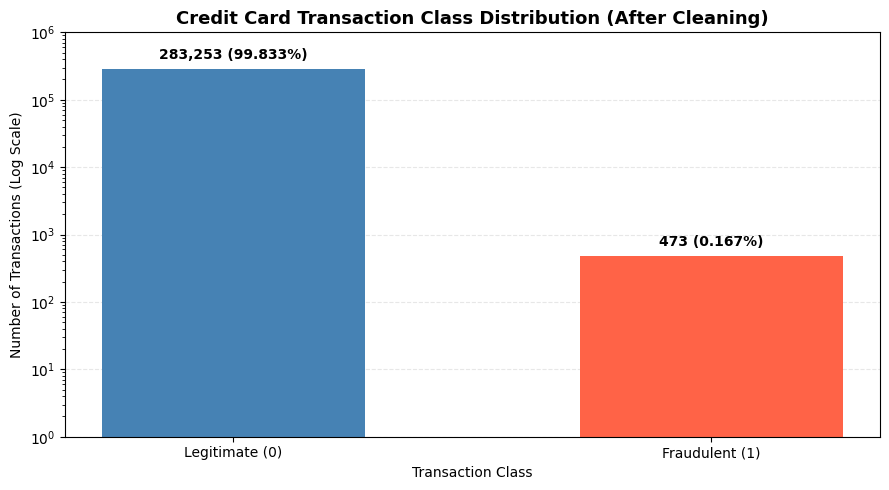

In [6]:

# Calculate class counts and percentages after cleaning
class_counts_clean = (
    creditcard_clean_df["Class"].value_counts().sort_index()
)

class_percentages_clean = (
    class_counts_clean / class_counts_clean.sum() * 100
)

# Define descriptive labels
class_labels = ["Legitimate (0)", "Fraudulent (1)"]

# Create the class distribution visualization
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    class_labels,
    class_counts_clean.values,
    color=["steelblue", "tomato"],
    width=0.55
)

# Use logarithmic scaling to highlight the minority class
ax.set_yscale("log")

# Add transaction counts and percentages above each bar
for bar, count, percentage in zip(
    bars, class_counts_clean.values, class_percentages_clean.values
):
    ax.annotate(
        f"{count:,} ({percentage:.3f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, count),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

# Add descriptive labels
ax.set_title(
    "Credit Card Transaction Class Distribution (After Cleaning)",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Transaction Class")
ax.set_ylabel("Number of Transactions (Log Scale)")
ax.set_ylim(1, 1_000_000)

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()



#### 5.4.1 Visualization Findings

The class distribution visualization confirms that legitimate transactions significantly outnumber fraudulent transactions.

After removing exact duplicates, the dataset contains 283,253 legitimate transactions and only 473 fraudulent transactions.

This severe class imbalance presents a challenge for Logistic Regression because a model may favor the majority class and still achieve high overall accuracy.

Therefore, the dataset will be divided using stratified sampling, and performance evaluation will include precision, recall, F1-score, and a confusion matrix in addition to accuracy.



### 5.5 Descriptive Statistics and Feature Analysis

Descriptive statistics help identify the central tendency, variability, and range of numerical features.

The dataset contains:
- **Time:** Seconds elapsed between each transaction and the first transaction in the dataset.
- **Amount:** Transaction amount.
- **V1–V28:** Anonymized numerical features obtained through Principal Component Analysis (PCA).
- **Class:** Binary target variable (0 = legitimate, 1 = fraudulent).

This analysis focuses on the `Time` and `Amount` features and compares transaction amounts across legitimate and fraudulent classes.

The results will help identify potential differences between transaction groups and inform preprocessing decisions.


In [7]:

# Descriptive statistics for Time and Amount
print("Descriptive Statistics for Time and Amount:")

display(
    creditcard_clean_df[["Time", "Amount"]]
    .describe()
    .T
    .round(2)
)

# Compare transaction amounts by class
print("\nTransaction Amount Statistics by Class:")

amount_by_class = (
    creditcard_clean_df
    .groupby("Class")["Amount"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

amount_by_class.index = [
    "Legitimate (0)",
    "Fraudulent (1)"
]

display(amount_by_class)

# Check transactions with zero amount
zero_amount_count = (
    creditcard_clean_df["Amount"] == 0
).sum()

print("\nTransactions with Zero Amount:", zero_amount_count)


Descriptive Statistics for Time and Amount:


,count,mean,std,min,25%,50%,75%,max
Time,283726.0,94811.08,47481.05,0.0,54204.75,84692.5,139298.00,172792.00
Amount,283726.0,88.47,250.40,0.0,5.60,22.0,77.51,25691.16



Transaction Amount Statistics by Class:


,count,mean,median,std,min,max
Legitimate (0),283253,88.41,22.00,250.38,0.0,25691.16
Fraudulent (1),473,123.87,9.82,260.21,0.0,2125.87



Transactions with Zero Amount: 1808



#### 5.5.1 Descriptive Statistics Findings

The descriptive statistical analysis of the cleaned dataset revealed the following:

**1. Transaction Time**
- The average transaction time is 94,811.08 seconds.
- Transaction times range from 0 to 172,792 seconds.
- Time is measured relative to the first transaction rather than as a calendar date.

**2. Transaction Amount**
- The average transaction amount is 88.47.
- The median transaction amount is 22.00.
- Transaction amounts range from 0 to 25,691.16.
- The mean is substantially higher than the median, indicating a right-skewed distribution influenced by large transactions.

**3. Comparison Between Transaction Classes**

| Statistic | Legitimate | Fraudulent |
|---|---:|---:|
| Mean Amount | 88.41 | 123.87 |
| Median Amount | 22.00 | 9.82 |
| Standard Deviation | 250.38 | 260.21 |
| Maximum Amount | 25,691.16 | 2,125.87 |

Fraudulent transactions have a higher mean amount (123.87) but a lower median amount (9.82) compared with legitimate transactions.

This suggests that some larger fraudulent transactions increase the average, even though at least half of fraudulent transactions involve relatively small amounts.

**4. Zero-Amount Transactions**

A total of 1,808 transactions have an amount of zero. These records will be retained because a zero amount does not necessarily indicate invalid data.

**Preprocessing Implications**

The `Time` and `Amount` features have different numerical scales from the anonymized PCA features. Therefore, feature standardization will be considered during Logistic Regression preprocessing.

The large differences between the mean and median also suggest that transaction amounts are right-skewed. Visual analysis will help examine these distributions further.



### 5.6 Transaction Amount Distribution by Class

This analysis compares transaction amount distributions between legitimate and fraudulent transactions.

A logarithmic transformation, `log(1 + Amount)`, is used for visualization because the original amounts are highly right-skewed.

Each class histogram is normalized independently to allow a meaningful comparison despite the large difference in class sizes.

This transformation is applied only to the visualization and does not modify the original dataset.


In [ ]:

# Extract transaction amounts for each class
legitimate_amounts = creditcard_clean_df.loc[
    creditcard_clean_df["Class"] == 0, "Amount"
]

fraudulent_amounts = creditcard_clean_df.loc[
    creditcard_clean_df["Class"] == 1, "Amount"
]

# Apply log(1 + Amount) for visualization only
legitimate_log = np.log1p(legitimate_amounts)
fraudulent_log = np.log1p(fraudulent_amounts)

# Use common histogram bins for a fair comparison
bins = np.linspace(
    0,
    np.log1p(creditcard_clean_df["Amount"].max()),
    60
)

# Create normalized histograms
fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    legitimate_log,
    bins=bins,
    density=True,
    alpha=0.5,
    color="steelblue",
    label="Legitimate (0)"
)

ax.hist(
    fraudulent_log,
    bins=bins,
    density=True,
    alpha=0.5,
    color="tomato",
    label="Fraudulent (1)"
)

# Format the visualization
ax.set_title(
    "Transaction Amount Distribution by Class",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Log(1 + Transaction Amount)")
ax.set_ylabel("Probability Density")
ax.legend(title="Transaction Class")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
